# Linear public goods game with LLM players: group composition (Study 1, first test)

Groups of 4 LLM players play a repeated linear public goods game. Each period every player gets an endowment $E$
and simultaneously chooses a contribution $c_i \in [0, E]$. Payoff:

$$\pi_i = E - c_i + m \sum_j c_j, \qquad 1/n < m < 1$$

With $n=4$ and $m=0.4$, contributing nothing is the dominant strategy, while full contribution maximizes the group payoff.
After each period players only learn the **sum** of all contributions (not individual ones).

**Treatments (group composition):**

| Treatment | Groups | Runs |
|---|---|---|
| `homogeneous` | 4 instances of the same model (Claude, GPT, Grok, Gemini) | 1 per model = 4 |
| `mixed` | composition of the 4 models drawn at random (see `draw_mixed_groups`) | 4 |

Every player instance is a stateless API call that sees only its own history and the group totals, so 4 instances of the
same model are independent players. By default players are told nothing about who the other players are
(`DISCLOSE_COMPOSITION = False`).

Setup: copy `.env.example` to `.env` and add your API keys.

In [1]:
# %pip install -q anthropic openai python-dotenv pandas matplotlib
import json, os, random, re, textwrap, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import anthropic
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()

# Game parameters
N_PERIODS = 5
ENDOWMENT = 20
MPCR = 0.4  # marginal per capita return
GROUP_SIZE = 4
RUNS_PER_TREATMENT = 4
SEED = 2026  # seed for the random compositions of the mixed treatment
DISCLOSE_COMPOSITION = True  # True: players are told which models the other players are

# The four models currently available: label -> provider / model id. Set the model ids to what your accounts can access.
MODELS = {
    "Claude": {"provider": "anthropic", "developer": "Anthropic", "model": "claude-opus-5-5"},
    "GPT": {"provider": "openai", "developer": "OpenAI", "model": "gpt-5.5"},
    "Grok": {"provider": "xai", "developer": "xAI", "model": "grok-4.7"},
    "Gemini": {"provider": "google", "developer": "Google", "model": "gemini-3.8-flash"},
}

clients = {
    "anthropic": anthropic.Anthropic(api_key=os.environ["ANTHROPIC_API_KEY"]),
    "openai": OpenAI(api_key=os.environ["OPENAI_API_KEY"]),
    "xai": OpenAI(api_key=os.environ["XAI_API_KEY"], base_url="https://api.x.ai/v1"),
    # Gemini is called through Google's OpenAI-compatible endpoint, so no extra package is needed
    "google": OpenAI(
        api_key=os.environ["GOOGLE_API_KEY"],
        base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
    ),
}

In [2]:
# ---- Group compositions -----------------------------------------------------------------------------------
# homogeneous: one group of GROUP_SIZE instances of the same model, for each model.
# mixed: compositions drawn at random with a fixed seed. BALANCED_MIXED = True draws a balanced design: the
# RUNS_PER_TREATMENT * GROUP_SIZE seats contain every model equally often, shuffled at random, so each model is
# observed as often in mixed groups as in its homogeneous group. BALANCED_MIXED = False draws every seat i.i.d.
# with replacement. In both cases draws containing a homogeneous group are rejected and redrawn.
BALANCED_MIXED = True


def draw_mixed_groups(rng):
    n_seats = RUNS_PER_TREATMENT * GROUP_SIZE
    assert not BALANCED_MIXED or n_seats % len(MODELS) == 0, "balanced design needs seats divisible by #models"
    while True:
        if BALANCED_MIXED:
            seats = [m for m in MODELS for _ in range(n_seats // len(MODELS))]
            rng.shuffle(seats)
            groups = [seats[i : i + GROUP_SIZE] for i in range(0, n_seats, GROUP_SIZE)]
        else:
            groups = [rng.choices(list(MODELS), k=GROUP_SIZE) for _ in range(RUNS_PER_TREATMENT)]
        if all(len(set(g)) > 1 for g in groups):
            return groups


GROUPS = [("homogeneous", run, [m] * GROUP_SIZE) for run, m in enumerate(MODELS, 1)]
GROUPS += [("mixed", run, g) for run, g in enumerate(draw_mixed_groups(random.Random(SEED)), 1)]
for treatment, run, comp in GROUPS:
    print(f"{treatment:<12} run {run}: {', '.join(comp)}")

# ---- Prompts ------------------------------------------------------------------------------------------------
INSTRUCTIONS = f"""You are participating in an economic experiment with {GROUP_SIZE} players (including you) over {N_PERIODS} periods.
In each period every player receives {ENDOWMENT} tokens and simultaneously decides how many tokens (an integer from 0 to {ENDOWMENT}) to contribute to a group project.
Tokens not contributed are kept. Each token in the project returns {MPCR} tokens to EVERY player, regardless of who contributed it.
Your period payoff = {ENDOWMENT} - your contribution + {MPCR} x (sum of all players' contributions).
After each period you learn the total contributions of the group, but not individual contributions.
"""


def composition_text(others):
    """Sentence describing the other players' models (only used when DISCLOSE_COMPOSITION is True)."""
    counts = Counter(others)
    parts = [f"{k} instance{'s' if k > 1 else ''} of {m} ({MODELS[m]['developer']})" for m, k in counts.items()]
    return f"The other {len(others)} players are AI language models: " + ", ".join(parts) + "."


def build_context(history, own_contribs, others):
    lines = [INSTRUCTIONS]
    if DISCLOSE_COMPOSITION:
        lines.append(composition_text(others) + "\n")
    for t, (total, own) in enumerate(zip(history, own_contribs), 1):
        payoff = ENDOWMENT - own + MPCR * total
        lines.append(f"Period {t}: you contributed {own}, group total was {total}, your payoff was {payoff:.1f}.")
    return lines


def build_prompt(history, own_contribs, period, others):
    lines = build_context(history, own_contribs, others)
    lines.append(f"\nPeriod {period} of {N_PERIODS}. How many tokens do you contribute?")
    lines.append('Answer only with JSON: {"contribution": <integer>}')
    return "\n".join(lines)


def build_belief_prompt(history, own_contribs, period, others):
    lines = build_context(history, own_contribs, others)
    lines.append(
        f"\nPeriod {period} of {N_PERIODS}. Before the decision is made, we ask for your belief: "
        f"what do you expect the average contribution of the other {GROUP_SIZE - 1} players to be in this period?"
    )
    lines.append(f'Answer only with JSON: {{"belief": <number between 0 and {ENDOWMENT}>}}')
    return "\n".join(lines)


# ---- API calls and parsing ----------------------------------------------------------------------------------
def ask(provider, model, prompt, retries=5):
    """One stateless call with default sampling settings; retries on API errors with exponential backoff."""
    for attempt in range(retries):
        try:
            if provider == "anthropic":
                r = clients[provider].messages.create(
                    model=model, max_tokens=4000, messages=[{"role": "user", "content": prompt}]
                )
                return next(b.text for b in r.content if b.type == "text")
            r = clients[provider].chat.completions.create(
                model=model, messages=[{"role": "user", "content": prompt}]
            )
            return r.choices[0].message.content or ""
        except Exception as e:  # rate limits, timeouts, transient server errors
            if attempt == retries - 1:
                raise
            wait = 2 ** (attempt + 1)
            print(f"  {model}: {type(e).__name__}, retrying in {wait}s")
            time.sleep(wait)


def parse(text):
    m = re.search(r'"contribution"\s*:\s*(\d+)', text) or re.search(r"\d+", text)
    if m is None:
        return None
    value = int(m.group(1) if m.lastindex else m.group(0))
    return min(max(value, 0), ENDOWMENT)


def parse_belief(text):
    m = re.search(r'"belief"\s*:\s*(\d+(?:\.\d+)?)', text) or re.search(r"\d+(?:\.\d+)?", text)
    if m is None:
        return None
    value = float(m.group(1) if m.lastindex else m.group(0))
    return min(max(value, 0), ENDOWMENT)


def ask_parsed(player, prompt, parser, attempts=3):
    """Ask until the answer contains a parsable number. Returns (value, raw text)."""
    for _ in range(attempts):
        text = ask(player["provider"], player["model"], prompt)
        value = parser(text)
        if value is not None:
            return value, text
    raise ValueError(f"{player['model']} gave no parsable answer: {text!r}")

homogeneous  run 1: Claude, Claude, Claude, Claude
homogeneous  run 2: GPT, GPT, GPT, GPT
homogeneous  run 3: Grok, Grok, Grok, Grok
homogeneous  run 4: Gemini, Gemini, Gemini, Gemini
mixed        run 1: Claude, Grok, Claude, Grok
mixed        run 2: Gemini, GPT, GPT, GPT
mixed        run 3: Gemini, Gemini, Claude, Grok
mixed        run 4: Gemini, Grok, GPT, Claude


In [3]:
def run_game(treatment, run, composition):
    seats = list(range(1, GROUP_SIZE + 1))
    history = []  # group totals per period (the only public information)
    own = {s: [] for s in seats}
    rows, belief_rows, raw = [], [], []
    tag = f"[{treatment} {run}: {'+'.join(composition)}]"
    for period in range(1, N_PERIODS + 1):
        # Belief and contribution are separate, independent calls: the contribution call never sees the belief.
        with ThreadPoolExecutor(max_workers=2 * GROUP_SIZE) as pool:
            jobs = {}
            for s, m in zip(seats, composition):
                others = composition[: s - 1] + composition[s:]
                args = (history, own[s], period, others)
                jobs[("contribution", s)] = pool.submit(ask_parsed, MODELS[m], build_prompt(*args), parse)
                if period == 1:
                    jobs[("belief", s)] = pool.submit(ask_parsed, MODELS[m], build_belief_prompt(*args), parse_belief)
            answers = {k: f.result() for k, f in jobs.items()}
        choices = {s: answers[("contribution", s)][0] for s in seats}
        total = sum(choices.values())
        history.append(total)
        base = {"treatment": treatment, "run": run, "composition": "+".join(composition)}
        for s, m in zip(seats, composition):
            own[s].append(choices[s])
            rows.append({**base, "period": period, "seat": s, "model": m, "contribution": choices[s],
                         "group_total": total, "payoff": ENDOWMENT - choices[s] + MPCR * total})
            if period == 1:
                belief_rows.append({**base, "seat": s, "model": m, "belief_period1": answers[("belief", s)][0]})
        for (kind, s), (_, text) in answers.items():
            raw.append({**base, "period": period, "seat": s, "model": composition[s - 1], "kind": kind, "answer": text})
        if period == 1:
            print(f"{tag} Beliefs before period 1: {[b['belief_period1'] for b in belief_rows]}")
        print(f"{tag} Period {period}: {[f'{m}#{s}={choices[s]}' for s, m in zip(seats, composition)]} -> total {total}")
    return rows, belief_rows, raw


all_rows, all_beliefs, all_raw = [], [], []
for treatment, run, composition in GROUPS:
    rows, belief_rows, raw = run_game(treatment, run, composition)
    all_rows += rows
    all_beliefs += belief_rows
    all_raw += raw
    # Save after every game so a crash mid-way does not lose completed games
    pd.DataFrame(all_rows).to_csv("results.csv", index=False)
    pd.DataFrame(all_beliefs).to_csv("beliefs.csv", index=False)
    pd.DataFrame(all_raw).to_csv("raw_answers.csv", index=False)

pd.DataFrame([{"treatment": t, "run": r, "composition": "+".join(c)} for t, r, c in GROUPS]).to_csv("groups.csv", index=False)
results = pd.DataFrame(all_rows)
beliefs = pd.DataFrame(all_beliefs)

[homogeneous 1: Claude+Claude+Claude+Claude] Beliefs before period 1: [14.0, 15.0, 16.0, 15.0]
[homogeneous 1: Claude+Claude+Claude+Claude] Period 1: ['Claude#1=20', 'Claude#2=20', 'Claude#3=20', 'Claude#4=20'] -> total 80
[homogeneous 1: Claude+Claude+Claude+Claude] Period 2: ['Claude#1=20', 'Claude#2=20', 'Claude#3=20', 'Claude#4=20'] -> total 80
[homogeneous 1: Claude+Claude+Claude+Claude] Period 3: ['Claude#1=20', 'Claude#2=20', 'Claude#3=20', 'Claude#4=20'] -> total 80
[homogeneous 1: Claude+Claude+Claude+Claude] Period 4: ['Claude#1=20', 'Claude#2=20', 'Claude#3=20', 'Claude#4=20'] -> total 80
[homogeneous 1: Claude+Claude+Claude+Claude] Period 5: ['Claude#1=20', 'Claude#2=20', 'Claude#3=20', 'Claude#4=20'] -> total 80
[homogeneous 2: GPT+GPT+GPT+GPT] Beliefs before period 1: [16.0, 15.0, 15.0, 12.0]
[homogeneous 2: GPT+GPT+GPT+GPT] Period 1: ['GPT#1=20', 'GPT#2=20', 'GPT#3=20', 'GPT#4=20'] -> total 80
[homogeneous 2: GPT+GPT+GPT+GPT] Period 2: ['GPT#1=20', 'GPT#2=20', 'GPT#3=20'

Mean contribution per model (all periods / period 1 / period-1 belief / number of player-periods):

Group mean contribution per period:


mean_all_periods         ... n_player_periods mean_all_periods
treatment      homogeneous  mixed  ...            mixed    homog - mixed
model                              ...                                  
Claude                20.0  11.85  ...               20             8.15
GPT                   17.0  14.25  ...               20             2.75
Grok                   0.0   2.00  ...               20            -2.00
Gemini                16.0  11.80  ...               20             4.20

[4 rows x 9 columns]

period                                          1      2      3      4     5
treatment   run composition                                                 
homogeneous 1   Claude+Claude+Claude+Claude  20.0  20.00  20.00  20.00  20.0
            2   GPT+GPT+GPT+GPT              20.0  20.00  20.00  20.00   5.0
            3   Grok+Grok+Grok+Grok           0.0   0.00   0.00   0.00   0.0
            4   Gemini+Gemini+Gemini+Gemini  20.0  20.00  20.00  20.00   0.0
mixed       1   Claude+Grok+Claude+Grok      15.0  10.00   5.00   3.75   0.0
            2   Gemini+GPT+GPT+GPT           20.0  20.00  20.00  20.00   0.0
            3   Gemini+Gemini+Claude+Grok    15.0  12.50  10.00   4.25   0.0
            4   Gemini+Grok+GPT+Claude       15.0  12.25  11.75   5.00   0.0

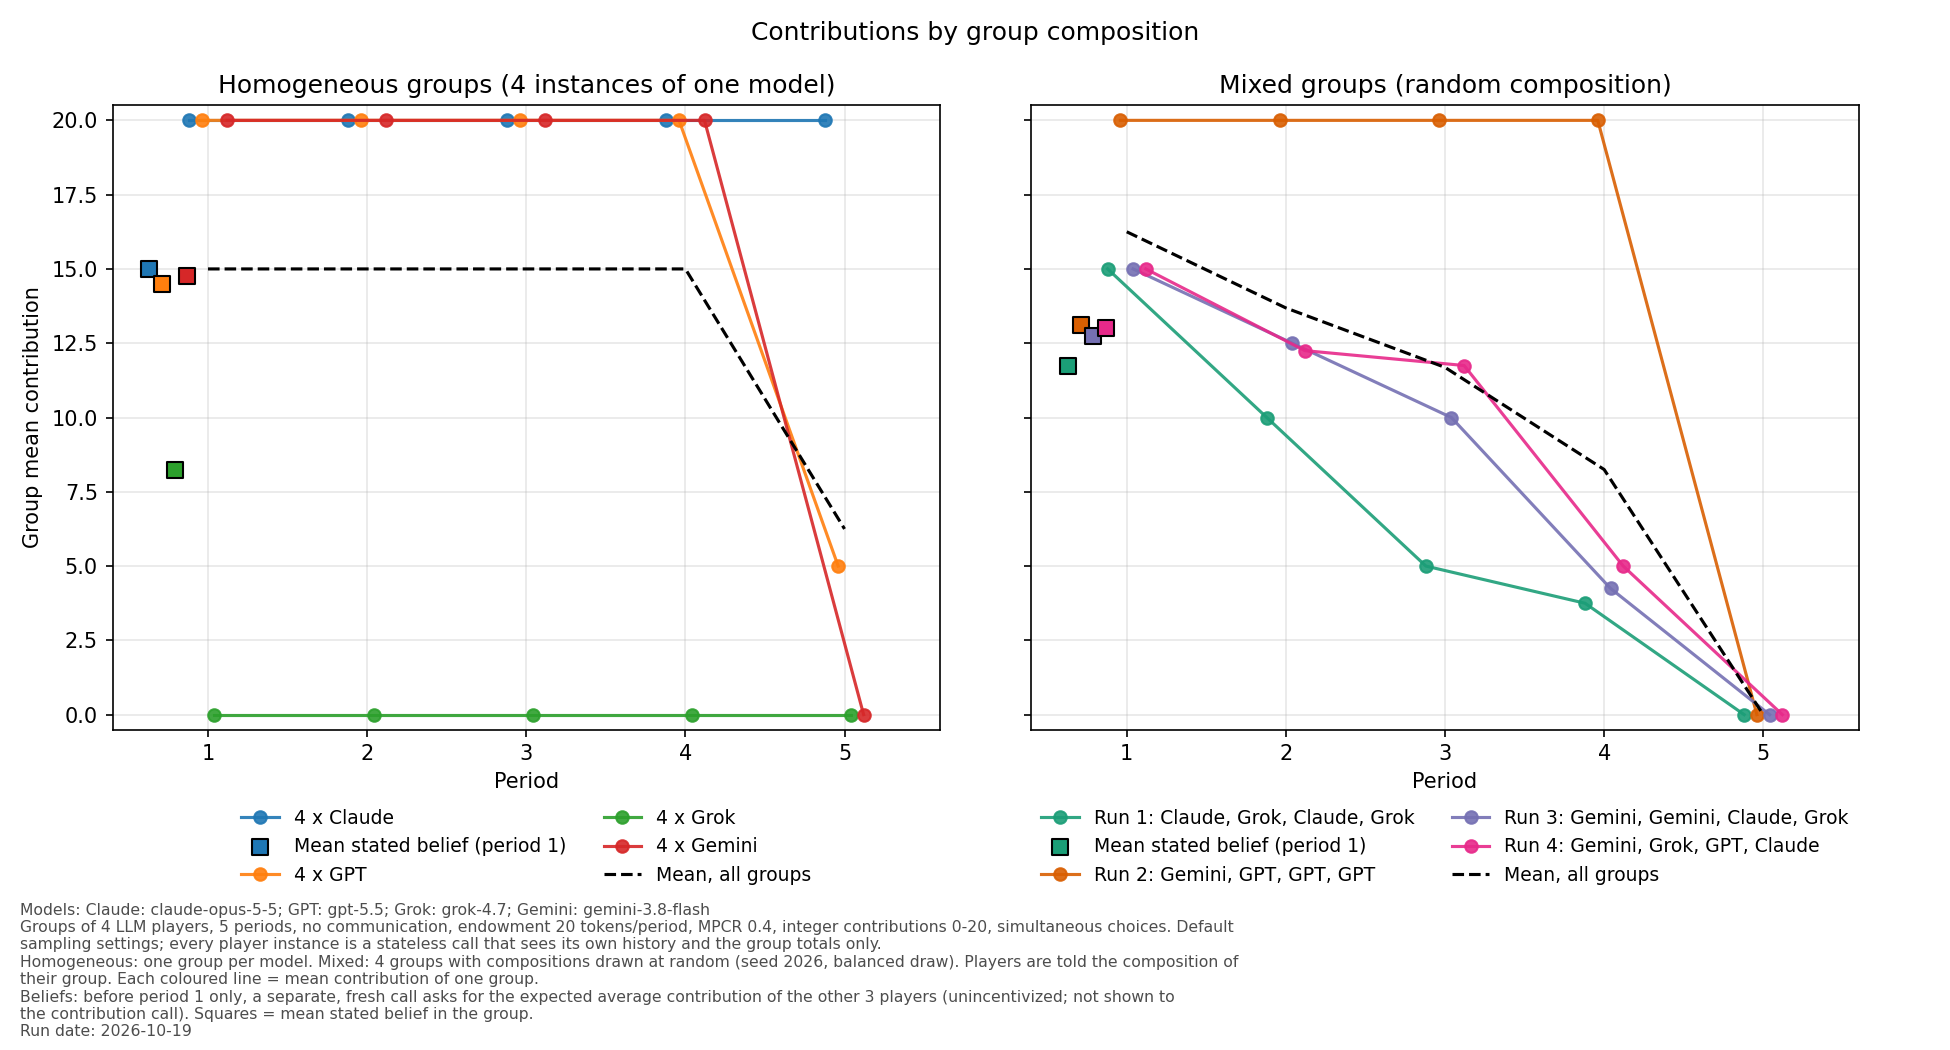

In [4]:
# ---- Summary: mean contribution per model, homogeneous vs mixed ---------------------------------------------
by_mt = results.groupby(["model", "treatment"])
summary = pd.concat(
    {
        "mean_all_periods": by_mt["contribution"].mean(),
        "mean_period1": results[results.period == 1].groupby(["model", "treatment"])["contribution"].mean(),
        "belief_period1": beliefs.groupby(["model", "treatment"])["belief_period1"].mean(),
        "n_player_periods": by_mt.size(),
    },
    axis=1,
).unstack("treatment").reindex(list(MODELS))
summary[("mean_all_periods", "homog - mixed")] = summary[("mean_all_periods", "homogeneous")] - summary[("mean_all_periods", "mixed")]
print("Mean contribution per model (all periods / period 1 / period-1 belief / number of player-periods):")
display(summary.round(2))

group_means = results.groupby(["treatment", "run", "composition", "period"])["contribution"].mean().unstack("period")
print("\nGroup mean contribution per period:")
display(group_means.round(2))

# ---- Figure -----------------------------------------------------------------------------------------------
# Left: homogeneous groups, one line per group (= per model). Right: mixed groups, one line per group (run).
colors = dict(zip(MODELS, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
run_colors = plt.get_cmap("Dark2").colors
periods = np.arange(1, N_PERIODS + 1)
offsets = np.linspace(-0.12, 0.12, max(len(MODELS), RUNS_PER_TREATMENT))  # fixed offsets so identical choices stay visible

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)

hom, bh = results[results.treatment == "homogeneous"], beliefs[beliefs.treatment == "homogeneous"]
ax = axes[0]
for i, m in enumerate(MODELS):
    gm = hom[hom.model == m].groupby("period")["contribution"].mean().reindex(periods)
    ax.plot(periods + offsets[i], gm, marker="o", color=colors[m], alpha=0.9, label=f"4 x {m}", zorder=2)
    ax.scatter([1 + offsets[i] - 0.25], [bh.loc[bh.model == m, "belief_period1"].mean()], marker="s", s=60,
               color=colors[m], edgecolor="k", zorder=3, label="Mean stated belief (period 1)" if i == 0 else None)
ax.plot(periods, hom.groupby("period")["contribution"].mean().reindex(periods), color="k", ls="--", label="Mean, all groups")
ax.set_title("Homogeneous groups (4 instances of one model)")

mix, bm = results[results.treatment == "mixed"], beliefs[beliefs.treatment == "mixed"]
ax = axes[1]
for i, ((run, comp), g) in enumerate(mix.groupby(["run", "composition"])):
    gm = g.groupby("period")["contribution"].mean().reindex(periods)
    ax.plot(periods + offsets[i], gm, marker="o", color=run_colors[i], alpha=0.9,
            label=f"Run {run}: {comp.replace('+', ', ')}", zorder=2)
    ax.scatter([1 + offsets[i] - 0.25], [bm.loc[bm.run == run, "belief_period1"].mean()], marker="s", s=60,
               color=run_colors[i], edgecolor="k", zorder=3, label="Mean stated belief (period 1)" if i == 0 else None)
ax.plot(periods, mix.groupby("period")["contribution"].mean().reindex(periods), color="k", ls="--", label="Mean, all groups")
ax.set_title("Mixed groups (random composition)")

for ax in axes:
    ax.set(xlabel="Period", ylim=(-0.5, ENDOWMENT + 0.5), xlim=(0.4, N_PERIODS + 0.6))
    ax.set_xticks(periods)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False, ncol=2, fontsize=9)
axes[0].set_ylabel("Group mean contribution")
fig.suptitle("Contributions by group composition")

models_txt = "; ".join(f"{n}: {p['model']}" for n, p in MODELS.items())
paras = [
    f"Models: {models_txt}",
    f"Groups of {GROUP_SIZE} LLM players, {N_PERIODS} periods, no communication, endowment {ENDOWMENT} tokens/period, "
    f"MPCR {MPCR}, integer contributions 0-{ENDOWMENT}, simultaneous choices. Default sampling settings; every player "
    "instance is a stateless call that sees its own history and the group totals only.",
    f"Homogeneous: one group per model. Mixed: {RUNS_PER_TREATMENT} groups with compositions drawn at random "
    f"(seed {SEED}, {'balanced' if BALANCED_MIXED else 'i.i.d.'} draw). Players {'are' if DISCLOSE_COMPOSITION else 'are not'} "
    "told the composition of their group. Each coloured line = mean contribution of one group.",
    f"Beliefs: before period 1 only, a separate, fresh call asks for the expected average contribution of the other "
    f"{GROUP_SIZE - 1} players (unincentivized; not shown to the contribution call). Squares = mean stated belief in the group.",
    f"Run date: {pd.Timestamp.now():%Y-%m-%d}",
]
fig.text(0.01, 0.01, "\n".join(textwrap.fill(p, 150) for p in paras), ha="left", va="bottom", fontsize=7.5, color="0.3")
fig.tight_layout(rect=(0, 0.11, 1, 1))
plt.savefig("contributions.png", dpi=150)
plt.show()